<a href="https://colab.research.google.com/github/IvyWanjiru/Amazon-reviews-nlp-timeseries-neuralnets/blob/main/Summative_Lab_Customer_Reviews_Analysis_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

**Dataset:** `amazon_reviews_lab.csv` – 997 Amazon product reviews (40 products, 2000–2014) – mostly e-readers/tablets (Nook, Kindle) and TV mounts, plus a few early movie reviews – with rating, review text, summary, timestamp and a sentiment label.

| Part | Goal |
|---|---|
| 1 | NLP: preprocess review text, find frequent words and bigrams, compare language across sentiment |
| 2 | Time series: review volume and rating trends, stationarity tests, ARIMA forecasting |
| 3 | Neural networks: TF-IDF + MLP to predict the 1–5 star rating, with systematic comparison |

## Part 1: NLP

In [1]:
import re, warnings, string
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from nltk.util import bigrams, trigrams
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

for r in ['punkt','punkt_tab','stopwords','wordnet','omw-1.4','averaged_perceptron_tagger','averaged_perceptron_tagger_eng']:
    nltk.download(r, quiet=True)

df = pd.read_csv('amazon_reviews_lab.csv')
print('Shape:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('\nRating distribution:'); print(df['rating'].value_counts().sort_index())
print('\nSentiment distribution:'); print(df['sentiment_label'].value_counts())
df.head(3)

Shape: (997, 9)
Missing values: 0

Rating distribution:
rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64

Sentiment distribution:
sentiment_label
positive    768
negative    135
neutral      94
Name: count, dtype: int64


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60


In [2]:
# Which sentiment label corresponds to which ratings? (so we know what the label means)
print(pd.crosstab(df['rating'], df['sentiment_label']))
print('\nReview length (words):'); print(df['review_length_words'].describe().round(1))

sentiment_label  negative  neutral  positive
rating                                      
1                      87        0         0
2                      48        0         0
3                       0       94         0
4                       0        0       188
5                       0        0       580

Review length (words):
count     997.0
mean      146.4
std       216.1
min         5.0
25%        32.0
50%        67.0
75%       165.0
max      2079.0
Name: review_length_words, dtype: float64


**Observations.** The data is heavily skewed towards 5★ reviews (~58%), and `sentiment_label` is just a re-binning of rating (1–2 → negative, 3 → neutral, 4–5 → positive). This class imbalance matters later for modelling.

### Preprocessing pipeline
Steps: lowercase → strip URLs and HTML → remove punctuation/digits → tokenize → keep alphabetic tokens → remove stopwords → lemmatize.

Design choices:
- **Negations are kept** (`not`, `no`, `never`, …). NLTK's default stopword list contains them, but dropping "not" from "not good" flips the meaning for sentiment, so I remove them from the stopword list.
- **Generic filler words** (`one`, `get`, `would`, `really`, …) are added as domain stopwords in a *second* variant because they carry no topic or sentiment information. Product names (nook, kindle, mount) are deliberately **kept**, since they are exactly what a support team would route on.
- **Lemmatization over stemming** because lemmas stay readable ("movies" → "movie") which helps interpretation of frequency charts.

In [3]:
lemmatizer = WordNetLemmatizer()
base_stops = set(stopwords.words('english'))
negations = {'no','nor','not','never',"don't",'dont','against'} | {w for w in base_stops if w.endswith("n't")}
stop_words = base_stops - negations
domain_stops = {'one','get','got','would','could','also','really','even','make','made','much','thing','im','ive'}  # generic filler, NOT product names

def preprocess_text(text, extra_stops=frozenset(), return_string=False):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)       # URLs
    text = re.sub(r'<[^>]+>', ' ', text)                       # HTML tags
    text = text.replace("can't", 'cannot').replace("won't", 'will not')
    text = re.sub(r"n't", ' not', text)                       # expand contractions so negation survives
    text = re.sub(r"[^a-z\s']", ' ', text)                     # punctuation/digits
    tokens = word_tokenize(text)
    tokens = [t.strip("'") for t in tokens]
    tokens = [t for t in tokens if t.isalpha() and len(t) > 1]  # alphabetic only
    tokens = [t for t in tokens if t not in stop_words and t not in extra_stops]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return ' '.join(tokens) if return_string else tokens

sample = df['review_text'].iloc[5]
print('RAW      :', sample[:250])
print('PROCESSED:', ' '.join(preprocess_text(sample))[:250])

RAW      : For the money you can't go wrong. Yes, it has a litlle play in the mechanism but, you can adjust your mounting to accomodate that. It works great and frees up counter space. I would do it all again. Why spend 3 times more.
PROCESSED: money not go wrong yes litlle play mechanism adjust mounting accomodate work great free counter space would spend time


Raw word count: 145,935 -> tokens kept: 70,119 (48%)
Empty after cleaning: 0
Vocabulary: 7,532 raw -> 6,592 after cleaning


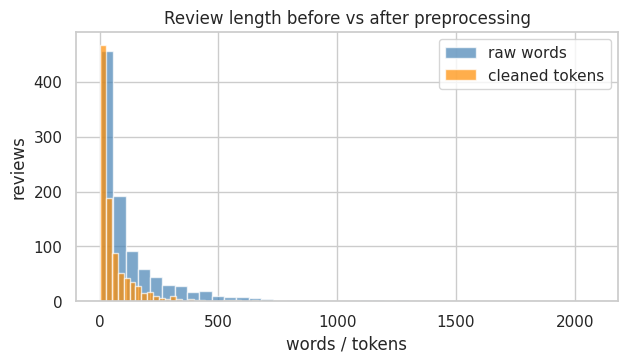

In [4]:
df['tokens_all']       = df['review_text'].apply(preprocess_text)                       # keeps movie/film etc.
df['processed_tokens'] = df['review_text'].apply(lambda t: preprocess_text(t, domain_stops)) # domain stops removed

# Validation of preprocessing quality
raw_words = df['review_text'].str.split().str.len().sum()
kept = df['processed_tokens'].str.len().sum()
print(f'Raw word count: {raw_words:,} -> tokens kept: {kept:,} ({kept/raw_words:.0%})')
print('Empty after cleaning:', int((df['processed_tokens'].str.len()==0).sum()))
vocab_raw = len({w for t in df['review_text'].str.lower().str.findall(r'[a-z]+') for w in t})
vocab_clean = len({w for t in df['processed_tokens'] for w in t})
print(f'Vocabulary: {vocab_raw:,} raw -> {vocab_clean:,} after cleaning')

fig, ax = plt.subplots(figsize=(7,3.5))
ax.hist(df['review_length_words'], bins=40, color='steelblue', alpha=.7, label='raw words')
ax.hist(df['processed_tokens'].str.len(), bins=40, color='darkorange', alpha=.7, label='cleaned tokens')
ax.set(title='Review length before vs after preprocessing', xlabel='words / tokens', ylabel='reviews'); ax.legend(); plt.show()

### Stemming vs lemmatization, sentence structure and parts of speech
I chose **lemmatization** over stemming. This cell checks that choice by comparing the two on the actual corpus, then looks at sentence length and which *parts of speech* carry sentiment.

In [5]:
from nltk.stem import PorterStemmer
from nltk.tokenize import sent_tokenize
stemmer = PorterStemmer()

demo = ['reading','readers','batteries','screens','mounted','returning','worked','books','useless','easily']
print(pd.DataFrame({'word':demo,
                    'Porter stem':[stemmer.stem(w) for w in demo],
                    'lemma (noun)':[lemmatizer.lemmatize(w) for w in demo],
                    'lemma (verb)':[lemmatizer.lemmatize(w,'v') for w in demo]}).to_string(index=False))

toks = [t for ts in df['processed_tokens'] for t in ts]
print(f'\nVocabulary after lemmatization: {len(set(toks)):,} | after stemming: {len({stemmer.stem(t) for t in toks}):,}')

# Sentence structure by sentiment
df['n_sentences'] = df['review_text'].apply(lambda t: len(sent_tokenize(t)))
print('\nSentences per review / words per review, by sentiment:')
print(df.groupby('sentiment_label')[['n_sentences','review_length_words']].mean().round(1))

     word Porter stem lemma (noun) lemma (verb)
  reading        read      reading         read
  readers      reader       reader      readers
batteries     batteri      battery    batteries
  screens      screen       screen       screen
  mounted       mount      mounted        mount
returning      return    returning       return
   worked        work       worked         work
    books        book         book         book
  useless     useless      useless      useless
   easily      easili       easily       easily

Vocabulary after lemmatization: 6,592 | after stemming: 5,090

Sentences per review / words per review, by sentiment:
                 n_sentences  review_length_words
sentiment_label                                  
negative                10.5                210.6
neutral                  9.0                195.5
positive                 6.7                129.1


In [6]:
# POS tagging: which adjectives and nouns characterise positive vs negative reviews?
def pos_words(texts, tag_prefix, n=12):
    c = Counter()
    for t in texts:
        for w, tag in nltk.pos_tag(word_tokenize(t.lower())):
            if tag.startswith(tag_prefix) and w.isalpha() and w not in stop_words and w not in domain_stops and len(w) > 2:
                c[lemmatizer.lemmatize(w)] += 1
    return c.most_common(n)

for lab in ['positive','negative']:
    texts = df.loc[df.sentiment_label==lab,'review_text']
    print(f'{lab.upper():9s} adjectives:', pos_words(texts,'JJ'))
    print(f'{lab.upper():9s} nouns     :', pos_words(texts,'NN'), '\n')

POSITIVE  adjectives: [('great', 370), ('good', 262), ('easy', 207), ('free', 148), ('little', 131), ('new', 120), ('nice', 112), ('best', 104), ('kindle', 101), ('noble', 100), ('able', 95), ('many', 92)]
POSITIVE  nouns     : [('nook', 1009), ('book', 615), ('screen', 314), ('tablet', 295), ('kindle', 269), ('device', 237), ('price', 232), ('mount', 208), ('time', 204), ('color', 200), ('card', 185), ('cable', 172)] 

NEGATIVE  adjectives: [('free', 48), ('good', 45), ('android', 40), ('noble', 37), ('able', 25), ('great', 24), ('first', 24), ('better', 24), ('new', 23), ('long', 20), ('available', 19), ('kindle', 18)]
NEGATIVE  nouns     : [('nook', 229), ('book', 191), ('device', 84), ('time', 80), ('card', 71), ('screen', 67), ('tablet', 66), ('kindle', 52), ('battery', 52), ('page', 52), ('problem', 46), ('customer', 42)] 



**Interpretation.**
- **Stemming vs lemmatization:** Porter stemming shrinks the vocabulary more (5,090 vs 6,592 types) but produces non-words such as *batteri* and *easili*, which makes charts hard to read. Lemmas stay readable (*batteries → battery*). The default noun lemmatizer misses verb forms (*mounted*, *returning*), so a POS-aware lemmatizer is a possible refinement.
- **Review structure:** Unhappy customers write more: negative reviews average ~10.5 sentences and ~211 words, against ~6.7 sentences and ~129 words for positive ones. Long, detailed complaints are typical (explaining a return or a billing problem).
- **POS tagging:** Positive reviews are described with evaluative adjectives (*great, good, easy, nice, best*). Negative reviews contain fewer such adjectives and more nouns of trouble (*problem, battery, customer, page*), and the adjectives *free* and *available* appear in complaints about free-book and app-store availability. The tagger mislabels some proper nouns as adjectives (*kindle, noble* from "Barnes & Noble"), a known limitation on informal product text.

### Word and bigram frequencies

Top 20 words: [('nook', 1580), ('not', 1261), ('book', 986), ('kindle', 592), ('screen', 536), ('like', 474), ('read', 464), ('work', 463), ('great', 444), ('tablet', 444), ('use', 432), ('tv', 427), ('no', 408), ('device', 399), ('good', 350), ('reader', 346), ('well', 336), ('time', 329), ('mount', 308), ('reading', 299)]

Top 15 bigrams: [('barnes noble', 166), ('nook color', 135), ('battery life', 98), ('touch screen', 96), ('sd card', 90), ('nook hd', 81), ('work great', 65), ('nook tablet', 64), ('work well', 61), ('kindle fire', 61), ('read book', 59), ('wall mount', 54), ('no problem', 53), ('wi fi', 48), ('simple touch', 45)]


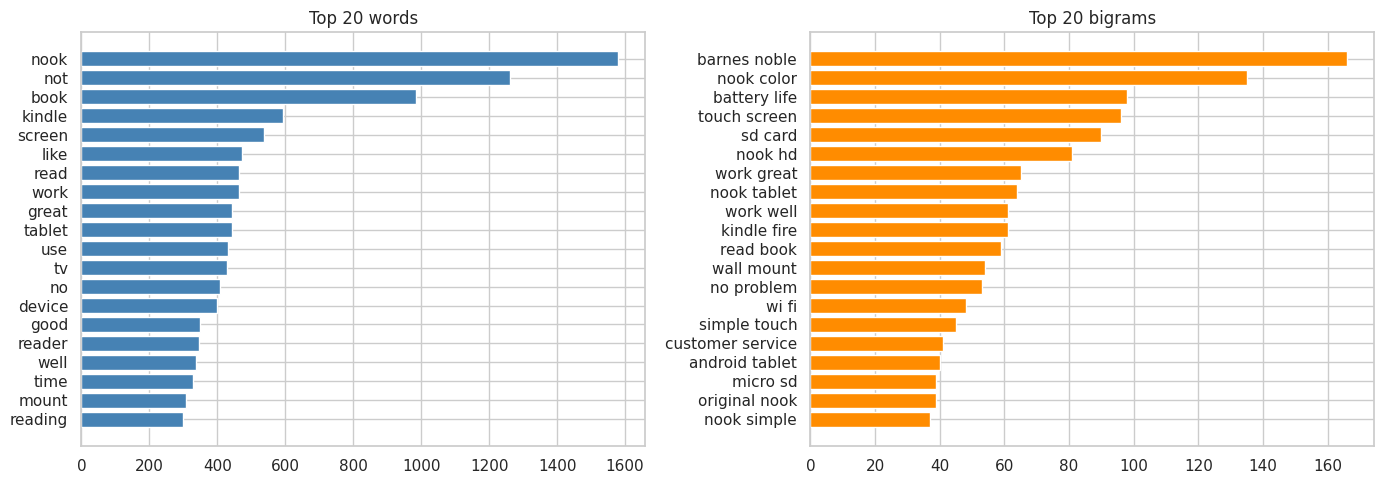

In [7]:
all_tokens = [t for toks in df['processed_tokens'] for t in toks]
word_freq = Counter(all_tokens)
print('Top 20 words:', word_freq.most_common(20))

all_bigrams = [bg for toks in df['processed_tokens'] for bg in bigrams(toks)]
bigram_freq = Counter(all_bigrams)
print('\nTop 15 bigrams:', [(' '.join(b),c) for b,c in bigram_freq.most_common(15)])

fig, axes = plt.subplots(1, 2, figsize=(14,5))
w, c = zip(*word_freq.most_common(20))
axes[0].barh(w[::-1], c[::-1], color='steelblue'); axes[0].set_title('Top 20 words')
b, c = zip(*[(' '.join(k),v) for k,v in bigram_freq.most_common(20)])
axes[1].barh(b[::-1], c[::-1], color='darkorange'); axes[1].set_title('Top 20 bigrams')
plt.tight_layout(); plt.show()

### Going further: language by sentiment, and distinctive terms

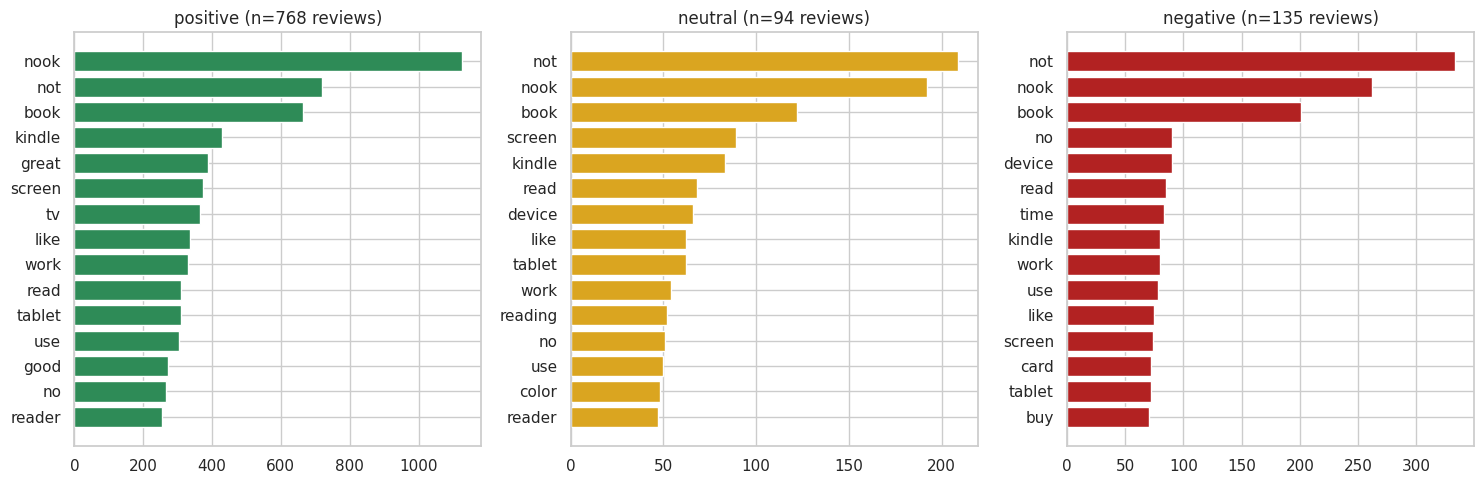

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15,5))
for ax, (lab, col) in zip(axes, [('positive','seagreen'),('neutral','goldenrod'),('negative','firebrick')]):
    toks = [t for ts in df.loc[df.sentiment_label==lab,'processed_tokens'] for t in ts]
    top = Counter(toks).most_common(15)
    w, c = zip(*top); ax.barh(w[::-1], c[::-1], color=col)
    ax.set_title(f'{lab} (n={int((df.sentiment_label==lab).sum())} reviews)')
plt.tight_layout(); plt.show()

In [9]:
# Words that are most distinctive: log-odds of appearing in negative vs positive reviews (with smoothing)
pos = Counter(t for ts in df.loc[df.sentiment_label=='positive','processed_tokens'] for t in ts)
neg = Counter(t for ts in df.loc[df.sentiment_label=='negative','processed_tokens'] for t in ts)
npos, nneg = sum(pos.values()), sum(neg.values())
rows = []
for w in set(pos)|set(neg):
    if pos[w]+neg[w] >= 15:
        lo = np.log((neg[w]+1)/(nneg+1)) - np.log((pos[w]+1)/(npos+1))
        rows.append((w, lo, pos[w], neg[w]))
lo_df = pd.DataFrame(rows, columns=['word','log_odds_neg_vs_pos','pos_count','neg_count']).sort_values('log_odds_neg_vs_pos')
print('Most POSITIVE-leaning words:'); print(lo_df.head(12).to_string(index=False))
print('\nMost NEGATIVE-leaning words:'); print(lo_df.tail(12).iloc[::-1].to_string(index=False))

Most POSITIVE-leaning words:
      word  log_odds_neg_vs_pos  pos_count  neg_count
      hdmi            -2.242281         64          1
       ink            -2.195029         30          0
  external            -2.195029         30          0
    listen            -2.019138         25          0
      stud            -1.959714         48          1
 perfectly            -1.939095         47          1
capability            -1.939095         23          0
   mounted            -1.829094         42          1
        wi            -1.756774         39          1
 bluetooth            -1.756774         19          0
  magazine            -1.739966         58          2
     photo            -1.705480         37          1

Most NEGATIVE-leaning words:
     word  log_odds_neg_vs_pos  pos_count  neg_count
    truck             3.253862          1         14
    route             3.084785          2         18
returning             2.973560          2         16
   credit             2.260

In [10]:
# Trigrams + bigrams within negative reviews only
neg_bi = Counter(bg for ts in df.loc[df.sentiment_label=='negative','processed_tokens'] for bg in bigrams(ts))
neg_tri = Counter(tg for ts in df.loc[df.sentiment_label=='negative','processed_tokens'] for tg in trigrams(ts))
print('Negative-review bigrams :', [(' '.join(k),v) for k,v in neg_bi.most_common(10)])
print('Negative-review trigrams:', [(' '.join(k),v) for k,v in neg_tri.most_common(8)])

# Effect of the domain-stopword choice
print('\nTop 10 WITHOUT domain stopwords removed:', Counter(t for ts in df['tokens_all'] for t in ts).most_common(10))

Negative-review bigrams : [('barnes noble', 39), ('customer service', 26), ('credit card', 21), ('battery life', 15), ('app store', 14), ('free book', 13), ('nook color', 13), ('kindle fire', 13), ('not work', 12), ('read book', 12)]
Negative-review trigrams: [('nook simple touch', 10), ('micro usb cable', 6), ('find free book', 5), ('limited app store', 5), ('scotia master card', 4), ('book barnes noble', 3), ('way directional key', 3), ('day battery life', 3)]

Top 10 WITHOUT domain stopwords removed: [('nook', 1580), ('not', 1261), ('book', 986), ('one', 596), ('kindle', 592), ('screen', 536), ('like', 474), ('read', 464), ('work', 463), ('great', 444)]


### Reflection – Part 1
**What the language says.** The vocabulary is dominated by product names and features: *nook*, *kindle*, *book*, *screen*, *tablet*, *mount*, and bigrams such as *barnes noble*, *nook color*, *battery life*, *touch screen*, *sd card*, *wall mount*. This tells us the corpus is mainly e-reader/tablet and TV-mount reviews. A support team could route on these terms directly (device line, battery, screen, storage, mounting hardware).

**Sentiment.** Generic positive words (*great*, *good*, *work*, *well*, *no problem*) are frequent overall, consistent with 77% of reviews being 4–5★. The negative reviews tell a different story: their distinctive terms are about **post-purchase service**, not product quality: *return/returning*, *credit (card)*, *customer service*, *truck*, *route*, *sent*, *fix*, *useless*, *poor*. Their top bigrams include *customer service*, *credit card*, *app store*, *battery life* and *not work*. In other words, unhappy customers are mostly writing about returns, billing and delivery problems, plus a few recurring product weaknesses (battery life, limited app store).

**Caution.** The most "positive-leaning" words (*hdmi*, *stud*, *mounted*, *magazine*, *ink*) are **topic words**, not opinion words: TV-mount reviews are simply happier than e-reader reviews. Word counts therefore mix *what is being reviewed* with *how people feel*, which matters for modelling in Part 3.

**Preprocessing impact.** Cleaning cut 146k raw words to ~70k tokens (48%) and the vocabulary from 7.5k to 6.6k with no empty reviews. Keeping negations was a deliberate choice: *not* is the 2nd most frequent token and *not work* shows up among the top negative bigrams; a default stopword list would have erased that signal. Remaining limits: spelling errors (*litlle*, *accomodate*) are not corrected, and lemmatization without POS tags leaves some verb forms unchanged.

## Part 2: Time Series

In [11]:
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = pd.read_csv('amazon_reviews_lab.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
print('Earliest:', df['timestamp'].min().date(), '| Latest:', df['timestamp'].max().date())

ts = df.set_index('timestamp').sort_index()
monthly_review_count = ts['rating'].resample('MS').count()
monthly_avg_rating   = ts['rating'].resample('MS').mean()
print('Months in span:', len(monthly_review_count), '| months with zero reviews:', int((monthly_review_count==0).sum()))
print('\nReviews per year:'); print(ts['rating'].resample('YS').count().rename(lambda d: d.year).to_string())

Earliest: 2000-05-12 | Latest: 2014-07-17
Months in span: 171 | months with zero reviews: 103

Reviews per year:
timestamp
2000      1
2001      0
2002      1
2003      0
2004      0
2005      2
2006      0
2007      1
2008      3
2009      9
2010    131
2011    164
2012    200
2013    325
2014    160


**Data caveat.** The sample is sparse in the early years: most months before 2010 have zero reviews, so the monthly average rating is undefined (`NaN`) for those months. I leave them as gaps rather than filling with zeros (a zero rating would be false), and use a rolling mean that ignores missing months.

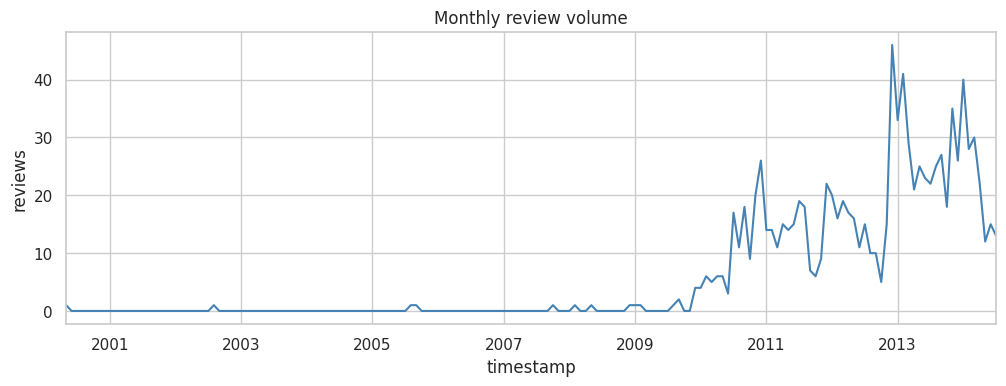

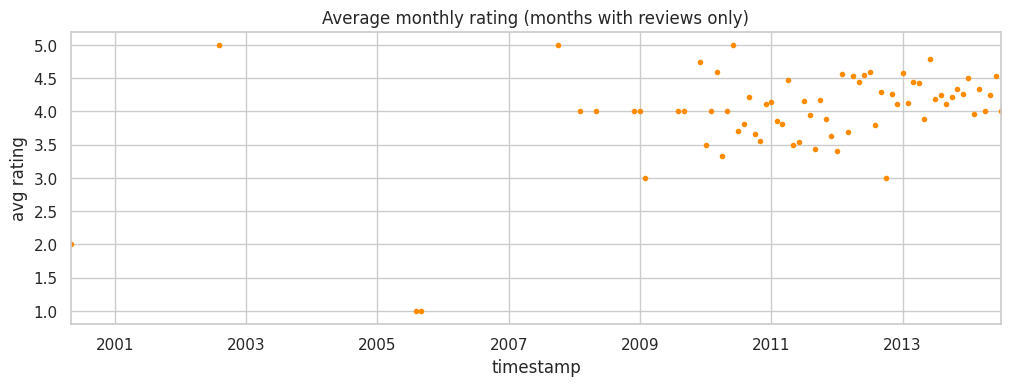

In [12]:
fig, ax = plt.subplots(figsize=(12,3.8))
monthly_review_count.plot(ax=ax, color='steelblue'); ax.set(title='Monthly review volume', ylabel='reviews'); plt.show()

fig, ax = plt.subplots(figsize=(12,3.8))
monthly_avg_rating.plot(ax=ax, marker='o', ms=3, lw=0, color='darkorange')
ax.set(title='Average monthly rating (months with reviews only)', ylabel='avg rating', ylim=(0.8,5.2)); plt.show()

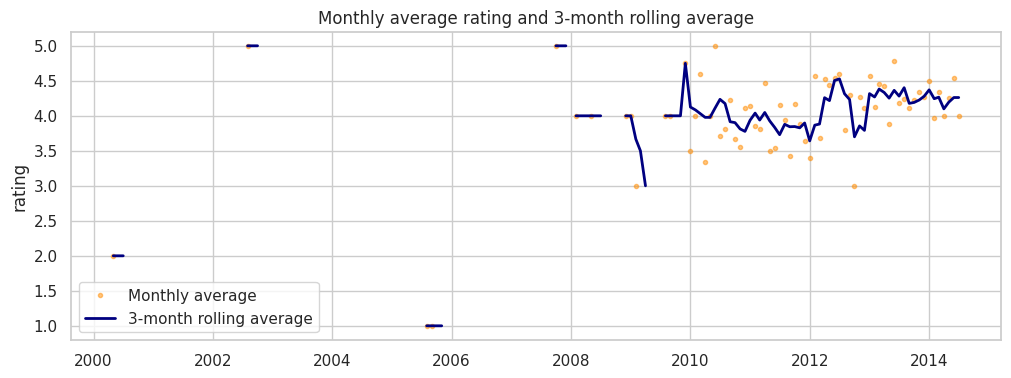

           count  mean
timestamp             
2000           1  2.00
2001           0   NaN
2002           1  5.00
2003           0   NaN
2004           0   NaN
2005           2  1.00
2006           0   NaN
2007           1  5.00
2008           3  4.00
2009           9  4.22
2010         131  3.91
2011         164  3.88
2012         200  4.14
2013         325  4.30
2014         160  4.25


In [13]:
rolling_3 = monthly_avg_rating.rolling(window=3, min_periods=1).mean()   # NaN months are skipped
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(monthly_avg_rating.index, monthly_avg_rating, 'o', ms=3, alpha=.5, label='Monthly average', color='darkorange')
ax.plot(rolling_3.index, rolling_3, lw=2, label='3-month rolling average', color='navy')
ax.set(title='Monthly average rating and 3-month rolling average', ylabel='rating', ylim=(0.8,5.2)); ax.legend(); plt.show()

yearly_rating = ts['rating'].resample('YS').agg(['count','mean']).rename(lambda d: d.year)
print(yearly_rating.round(2))

### Stationarity and transformation
Review volume only becomes continuous from **2010** (131 reviews that year vs. 14 in all of 2000–2009), so I model monthly counts from January 2010 onward and test stationarity there.

In [14]:
active = monthly_review_count[monthly_review_count.index >= '2010-01-01']
print('Modelling window:', active.index.min().date(), '->', active.index.max().date(), '| n =', len(active))

def stationarity_report(series, name):
    s = series.dropna()
    adf_p  = adfuller(s, autolag='AIC')[1]
    kpss_p = kpss(s, regression='c', nlags='auto')[1]
    verdict = 'stationary' if (adf_p<0.05 and kpss_p>0.05) else ('non-stationary' if (adf_p>=0.05 and kpss_p<=0.05) else 'inconclusive / conflicting')
    print(f'{name:34s} ADF p={adf_p:.4f} | KPSS p={kpss_p:.4f} -> {verdict}')

stationarity_report(active, 'Raw monthly counts')
stationarity_report(np.log1p(active), 'log(1+count)')
stationarity_report(active.diff(), 'First difference')
stationarity_report(np.log1p(active).diff(), 'log(1+count), first difference')
stationarity_report(active.diff(12), 'Seasonal difference (12)')

Modelling window: 2010-01-01 -> 2014-07-01 | n = 55
Raw monthly counts                 ADF p=0.7457 | KPSS p=0.0161 -> non-stationary
log(1+count)                       ADF p=0.0049 | KPSS p=0.0134 -> inconclusive / conflicting
First difference                   ADF p=0.0001 | KPSS p=0.1000 -> stationary
log(1+count), first difference     ADF p=0.0003 | KPSS p=0.1000 -> stationary
Seasonal difference (12)           ADF p=0.2947 | KPSS p=0.1000 -> inconclusive / conflicting


/tmp/ipykernel_2907/1166025085.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_p = kpss(s, regression='c', nlags='auto')[1]
/tmp/ipykernel_2907/1166025085.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_p = kpss(s, regression='c', nlags='auto')[1]
/tmp/ipykernel_2907/1166025085.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_p = kpss(s, regression='c', nlags='auto')[1]


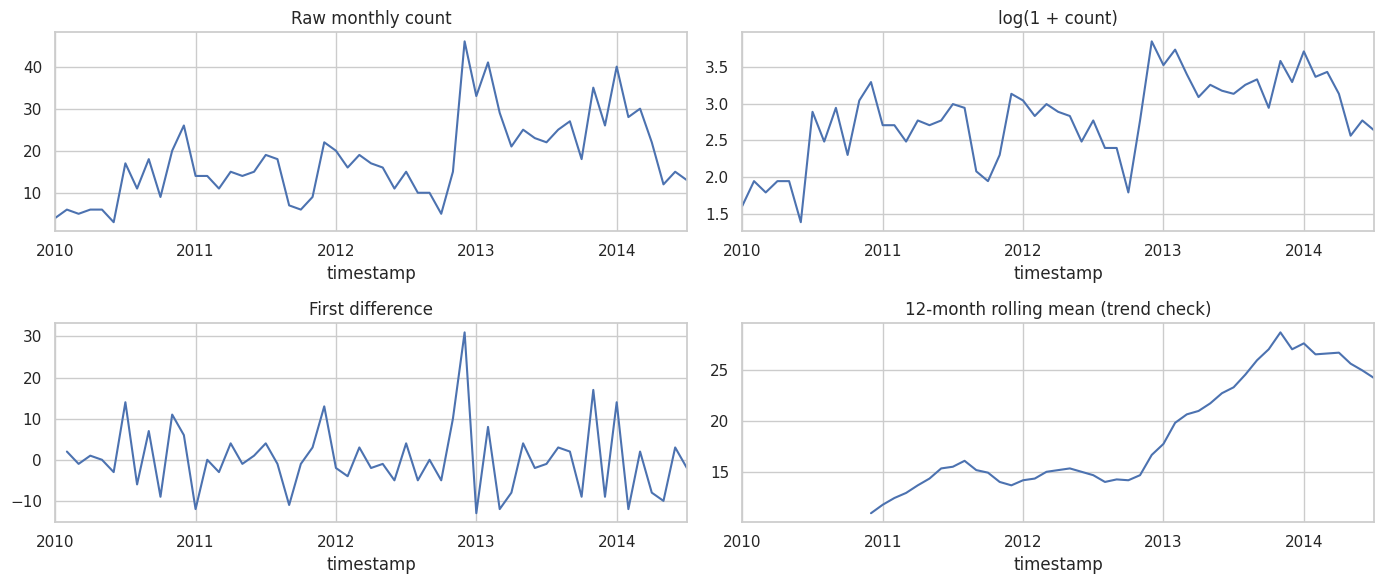

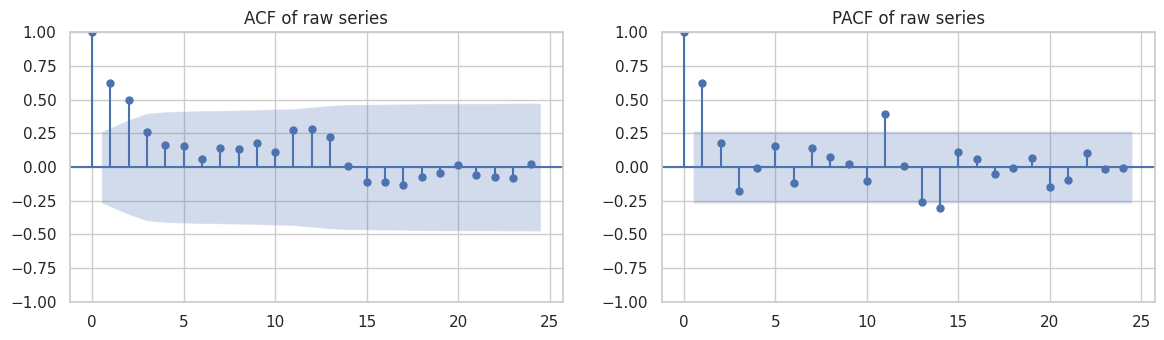

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14,6))
active.plot(ax=axes[0,0], title='Raw monthly count')
np.log1p(active).plot(ax=axes[0,1], title='log(1 + count)')
active.diff().plot(ax=axes[1,0], title='First difference')
active.rolling(12).mean().plot(ax=axes[1,1], title='12-month rolling mean (trend check)')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14,3.5))
plot_acf(active, lags=24, ax=axes[0], title='ACF of raw series'); plot_pacf(active, lags=24, ax=axes[1], title='PACF of raw series', method='ywm')
plt.show()

### Seasonal decomposition
Splits the monthly count into trend, seasonal and residual parts (period = 12 months) to see whether a seasonal term is needed.

Summary statistics of monthly review counts (2010 onward):
count    55.0
mean     17.8
std       9.7
min       3.0
25%      11.0
50%      16.0
75%      22.5
max      46.0
Name: rating, dtype: float64


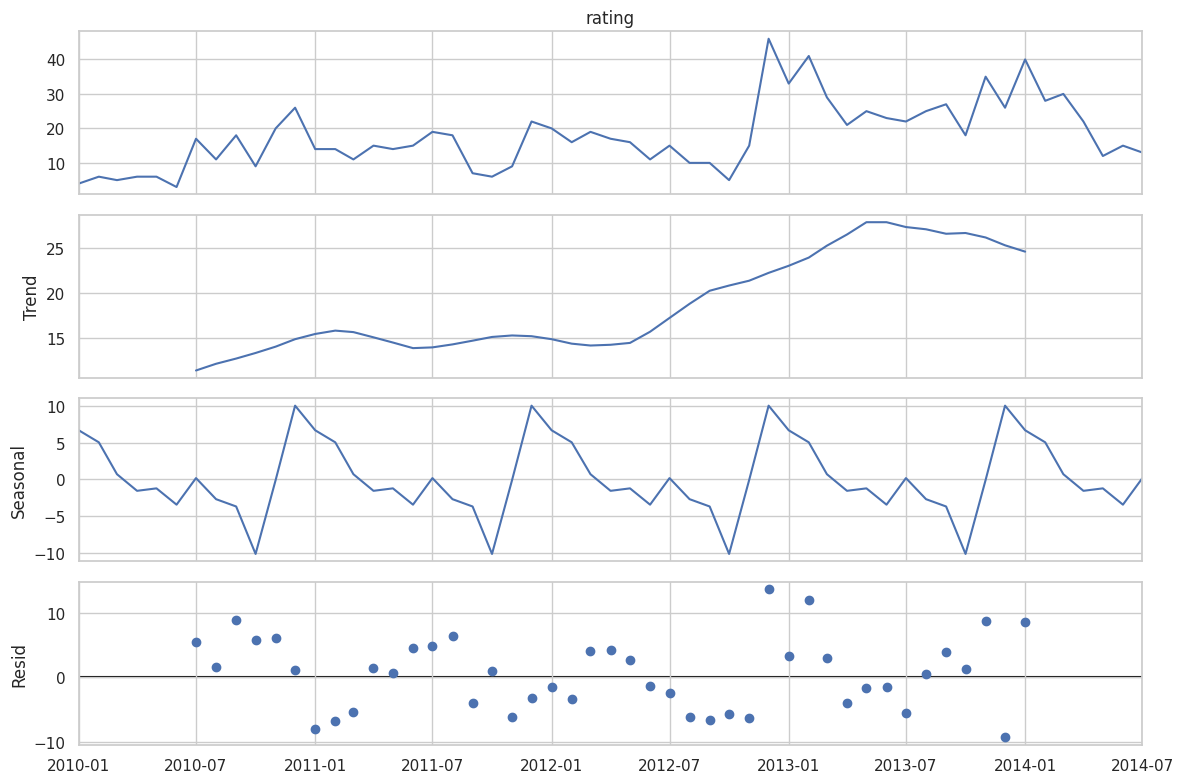

Seasonal strength (0 = none, 1 = strong): 0.47
Average seasonal effect by calendar month (reviews):
timestamp
1      6.7
2      5.0
3      0.7
4     -1.5
5     -1.2
6     -3.4
7      0.2
8     -2.7
9     -3.7
10   -10.1
11    -0.1
12    10.0


In [16]:
from statsmodels.tsa.seasonal import seasonal_decompose
print('Summary statistics of monthly review counts (2010 onward):'); print(active.describe().round(1))

dec = seasonal_decompose(active, model='additive', period=12)
fig = dec.plot(); fig.set_size_inches(12,8); plt.tight_layout(); plt.show()

seasonal_strength = max(0, 1 - dec.resid.var() / (dec.resid + dec.seasonal).var())
print(f'Seasonal strength (0 = none, 1 = strong): {seasonal_strength:.2f}')
print('Average seasonal effect by calendar month (reviews):')
print(pd.Series(dec.seasonal.groupby(dec.seasonal.index.month).mean().round(1)).to_string())

**Interpretation.** The decomposition shows a clear upward trend and a moderate seasonal component (strength ≈ 0.47). The calendar-month averages put the peaks in **December (+10 reviews) and January (+7)** and the trough in **October (−10)**. A holiday-gift explanation is plausible for e-readers and tablets (people review devices they received at Christmas), though I have not tested it. Caution: 55 months is only about four full years, so these seasonal estimates rest on four observations per month and are noisy; they are a hypothesis for a SARIMA model once more data is available, not a proven effect.

### Interpretation – stationarity
- **Raw monthly counts are non-stationary**: ADF cannot reject a unit root (p = 0.75) and KPSS rejects stationarity (p = 0.016). This matches the plots: volume trends upward from 2010 to a peak in 2013.
- **log(1+count)** helps the variance but leaves a conflicting verdict (ADF says stationary, KPSS says not), so a transformation alone is not enough: there is still a trend.
- **First differencing** passes both tests (ADF p = 0.0001, KPSS p = 0.10), so **d = 1** is justified; adding the log first (p = 0.0003) also works. I use the plain first difference so forecasts stay in review counts.
- A **seasonal difference (12)** is not clearly stationary (ADF p = 0.29) and the decomposition above does show moderate seasonality (December/January peak), but with only 55 months (<5 years) a seasonal ARIMA term would be estimated from about four cycles, so I keep the model non-seasonal and flag SARIMA as a next step.

In [17]:
# ---- Train / test split (last 12 months held out) ----
train, test = active.iloc[:-12], active.iloc[-12:]

# Candidate models: compare by AIC/BIC (in-sample) AND by out-of-sample error
candidates = {'AR(1)':(1,0,0),'AR(2)':(2,0,0),'MA(1)':(0,0,1),'ARMA(1,1)':(1,0,1),
              'ARIMA(1,1,1)':(1,1,1),'ARIMA(2,1,2)':(2,1,2),'ARIMA(0,1,1)':(0,1,1)}
rows, fits = [], {}
for name, order in candidates.items():
    try:
        res = ARIMA(train, order=order).fit()
        fc = res.forecast(12).clip(lower=0)
        rows.append((name, res.aic, res.bic, mean_absolute_error(test, fc), np.sqrt(mean_squared_error(test, fc))))
        fits[name] = res
    except Exception as e:
        print(name, 'failed:', e)

# naive benchmarks
naive_last = pd.Series(train.iloc[-1], index=test.index); naive_mean = pd.Series(train.mean(), index=test.index)
for nm, fc in [('Naive (last value)',naive_last),('Naive (train mean)',naive_mean)]:
    rows.append((nm, np.nan, np.nan, mean_absolute_error(test, fc), np.sqrt(mean_squared_error(test, fc))))

results = pd.DataFrame(rows, columns=['model','AIC','BIC','MAE','RMSE']).set_index('model').round(2)
print(results.sort_values('MAE'))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


                       AIC     BIC   MAE   RMSE
model                                          
ARIMA(0,1,1)        294.58  298.05  7.17   8.49
ARIMA(1,1,1)        293.08  298.29  7.23   8.57
ARIMA(2,1,2)        295.93  304.62  7.24   8.47
Naive (last value)     NaN     NaN  7.25   8.61
AR(2)               300.05  307.09  8.66  11.01
ARMA(1,1)           300.10  307.14  8.69  11.04
AR(1)               298.24  303.52  8.83  11.17
MA(1)               305.38  310.67  9.42  11.61
Naive (train mean)     NaN     NaN  9.57  11.69


Lowest AIC: ARIMA(1,1,1) | Lowest test MAE: ARIMA(0,1,1)

Ljung-Box test on residuals (p>0.05 => no leftover autocorrelation):
    lb_stat  lb_pvalue
6     6.470      0.373
12    9.953      0.620


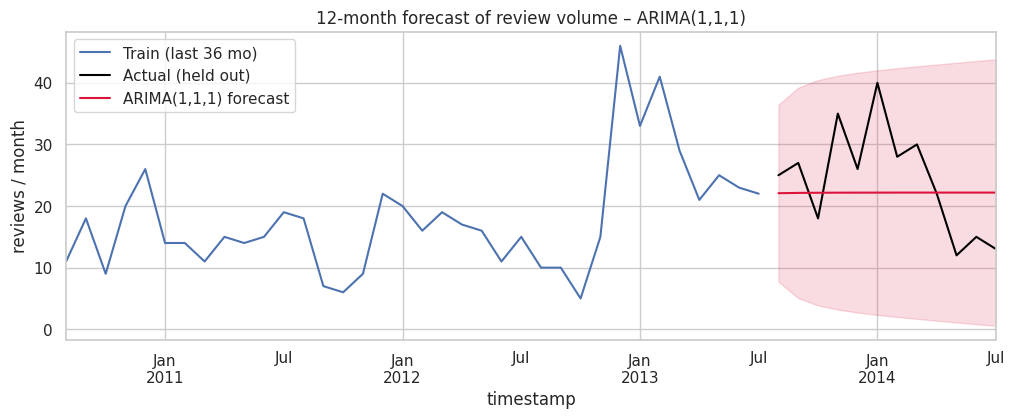

In [18]:
best_aic = results['AIC'].dropna().idxmin(); best_mae = results.loc[list(candidates)]['MAE'].idxmin()
print('Lowest AIC:', best_aic, '| Lowest test MAE:', best_mae)

# Residual diagnostics for the AIC-best model
from statsmodels.stats.diagnostic import acorr_ljungbox
res = fits[best_aic]
print('\nLjung-Box test on residuals (p>0.05 => no leftover autocorrelation):')
print(acorr_ljungbox(res.resid[1:], lags=[6,12]).round(3))

fc_obj = res.get_forecast(12); fc = fc_obj.predicted_mean.clip(lower=0); ci = fc_obj.conf_int().clip(lower=0)
fig, ax = plt.subplots(figsize=(12,4))
train.iloc[-36:].plot(ax=ax, label='Train (last 36 mo)'); test.plot(ax=ax, label='Actual (held out)', color='black')
fc.plot(ax=ax, label=f'{best_aic} forecast', color='crimson'); ax.fill_between(ci.index, ci.iloc[:,0], ci.iloc[:,1], color='crimson', alpha=.15)
ax.set(title=f'12-month forecast of review volume – {best_aic}', ylabel='reviews / month'); ax.legend(); plt.show()

                               SARIMAX Results                                
Dep. Variable:                 rating   No. Observations:                   43
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -143.539
Date:                Fri, 16 Oct 2026   AIC                            293.077
Time:                        18:40:16   BIC                            298.290
Sample:                    01-01-2010   HQIC                           294.988
                         - 07-01-2013                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5330      0.443      1.204      0.229      -0.335       1.401
ma.L1         -0.8887      0.271     -3.282      0.001      -1.419      -0.358
sigma2        53.6666      6.863      7.820      0.0

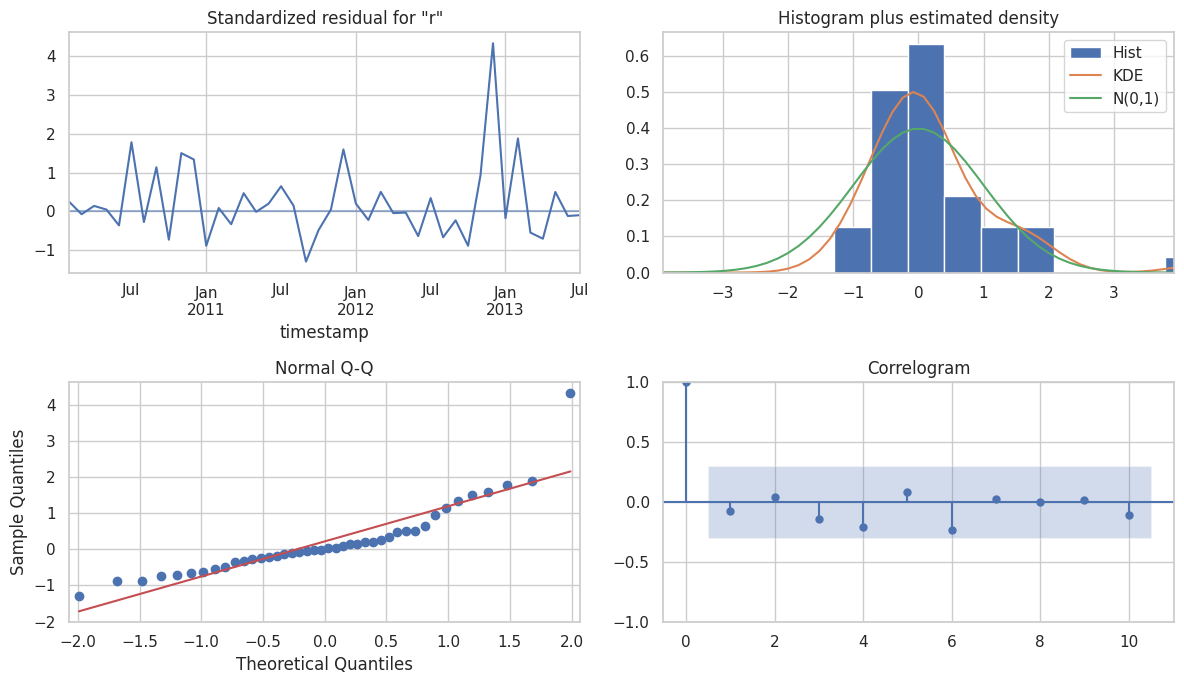

In [19]:
print(res.summary())
res.plot_diagnostics(figsize=(12,7)); plt.tight_layout(); plt.show()

In [20]:
# ---- Forecast the monthly average rating too (quarterly, to reduce the noise from sparse months) ----
q_rating = ts.loc['2010':, 'rating'].resample('QS').mean().dropna()
q_train, q_test = q_rating.iloc[:-4], q_rating.iloc[-4:]
q_res = ARIMA(q_train.values, order=(1,0,0)).fit()   # integer index: quarters with no reviews were dropped
q_fc = pd.Series(q_res.forecast(4), index=q_test.index)
print('Quarterly avg rating – AR(1) MAE:', round(mean_absolute_error(q_test, q_fc),3),
      '| naive-mean MAE:', round(mean_absolute_error(q_test, pd.Series(q_train.mean(), index=q_test.index)),3))
print(pd.DataFrame({'actual':q_test,'forecast':q_fc}).round(2))

Quarterly avg rating – AR(1) MAE: 0.152 | naive-mean MAE: 0.174
            actual  forecast
timestamp                   
2013-10-01    4.29      4.11
2014-01-01    4.30      4.09
2014-04-01    4.22      4.07
2014-07-01    4.00      4.07


### Reflection – Part 2
**Trends.** Review activity is essentially a post-2010 phenomenon: 14 reviews in 2000–2009, then 131 (2010), 164, 200, **325 (2013)**, and 160 in the first 6½ months of 2014 (a partial year, so roughly on pace with 2013, not a collapse). Average ratings dipped slightly in 2010–2011 (3.9) and rose to about 4.3 in 2013–2014; the 3-month rolling average smooths out noisy months. Months with few reviews swing wildly (a single 1★ review moves a small month a lot), which is why the rolling average is more trustworthy than individual points.

**Model selection (hold-out = last 12 months).** ARIMA(1,1,1) has the lowest AIC (293.1), ARIMA(0,1,1) the lowest hold-out MAE (7.17 reviews/month), and the models with d = 1 clearly beat the stationary AR/MA models (MAE 8.7–9.4) and the train-mean benchmark (9.6). ACF/PACF of the raw series show slow decay, consistent with needing differencing. Residual Ljung-Box tests (p = 0.37 at lag 6, 0.62 at lag 12) show no leftover autocorrelation. The model summary adds two caveats: the AR(1) coefficient is not significant (p = 0.23) so the simpler ARIMA(0,1,1) is nearly as good (and has the lower hold-out error), and the residuals are not normal (Jarque-Bera p < 0.001, skew 1.9, kurtosis 8.5), because of occasional spikes in review volume. The 95% forecast band should therefore be read as approximate.

**Honest caveat.** The best ARIMA only edges out the naive "repeat last value" forecast (MAE 7.17 vs 7.25), so there is little predictable structure beyond the level of the series. With ~43 training months and a mean of about 20 reviews/month, an MAE of ~7 is roughly 35% error; forecasts are best treated as a rough planning range (see the confidence band), not a precise target.

**Rating forecast.** A quarterly AR(1) gives MAE 0.15 stars against 0.17 for a constant mean, i.e. average ratings are close to a stable ~4.1–4.3 with little forecastable movement. The last quarter (July 2014) contains only 17 days of data, which explains the 4.00 actual.

## Part 3: Neural Networks

In [21]:
import os; os.environ['TF_CPP_MIN_LOG_LEVEL']='3'
import torch   # PyTorch is imported and trained BEFORE TensorFlow is imported (see note below)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight
from sklearn.linear_model import LogisticRegression

np.random.seed(42)
df = pd.read_csv('amazon_reviews_lab.csv')

# X = cleaned review text, y = rating shifted to 0..4
X_text = df['review_text'].apply(lambda t: preprocess_text(t, return_string=True))
y = df['rating'] - 1
print('Class counts (0=1★ ... 4=5★):', np.bincount(y))
print('Majority-class baseline accuracy:', round(np.bincount(y).max()/len(y),3))

Class counts (0=1★ ... 4=5★): [ 87  48  94 188 580]
Majority-class baseline accuracy: 0.582


In [22]:
# Split BEFORE fitting TF-IDF so the vectorizer never sees test data (avoids leakage)
Xtr_text, Xte_text, ytr, yte = train_test_split(X_text, y, test_size=0.2, stratify=y, random_state=42)
Xtr_text, Xva_text, ytr, yva = train_test_split(Xtr_text, ytr, test_size=0.15, stratify=ytr, random_state=42)

vectorizer = TfidfVectorizer(max_features=3000, ngram_range=(1,2), min_df=2, sublinear_tf=True)
Xtr = vectorizer.fit_transform(Xtr_text).toarray().astype('float32')
Xva = vectorizer.transform(Xva_text).toarray().astype('float32')
Xte = vectorizer.transform(Xte_text).toarray().astype('float32')
print('Feature matrix:', Xtr.shape, Xva.shape, Xte.shape)

ytr_oh, yva_oh, yte_oh = [np.eye(5, dtype='float32')[v.values] for v in (ytr, yva, yte)]
cw = dict(enumerate(compute_class_weight('balanced', classes=np.arange(5), y=ytr)))
print('Class weights:', {k: round(v,2) for k,v in cw.items()})

Feature matrix: (677, 3000) (120, 3000) (200, 3000)
Class weights: {0: np.float64(2.26), 1: np.float64(4.23), 2: np.float64(2.12), 3: np.float64(1.07), 4: np.float64(0.34)}


### Framework 1 of 2: PyTorch
To check that the result does not depend on one framework, I build the same architecture in **PyTorch and in Keras**: 256-64 hidden units, ReLU, dropout 0.5, class-weighted loss, RMSprop with Keras-equivalent settings, early stopping on validation loss. PyTorch is imported and trained *before* TensorFlow is imported: in some environments (including the one I tested in) merely importing TensorFlow first makes PyTorch training crash with a segmentation fault. The Keras models follow below.

In [23]:
import torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
torch.manual_seed(42)

to_t = lambda a: torch.tensor(a, dtype=torch.float32)
Xtr_t, Xva_t, Xte_t = to_t(Xtr), to_t(Xva), to_t(Xte)
ytr_t, yva_t = torch.tensor(ytr.values, dtype=torch.long), torch.tensor(yva.values, dtype=torch.long)

torch_model = nn.Sequential(nn.Linear(Xtr.shape[1],256), nn.ReLU(), nn.Dropout(0.5),
                            nn.Linear(256,64), nn.ReLU(), nn.Dropout(0.5),
                            nn.Linear(64,5))                      # raw logits: CrossEntropyLoss applies softmax
class_w = torch.tensor([cw[k] for k in range(5)], dtype=torch.float32)
train_loss_fn = nn.CrossEntropyLoss(weight=class_w)
val_loss_fn   = nn.CrossEntropyLoss()                              # unweighted, like Keras val_loss
opt = optim.RMSprop(torch_model.parameters(), lr=1e-3, alpha=0.9, eps=1e-7)
loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=32, shuffle=True)

best_loss, wait, best_state, tl_hist, vl_hist = np.inf, 0, None, [], []
for epoch in range(60):
    torch_model.train(); tot = 0
    for xb, yb in loader:
        opt.zero_grad(); loss = train_loss_fn(torch_model(xb), yb); loss.backward(); opt.step(); tot += loss.item()*len(xb)
    torch_model.eval()
    with torch.no_grad(): vl = val_loss_fn(torch_model(Xva_t), yva_t).item()
    tl_hist.append(tot/len(Xtr_t)); vl_hist.append(vl)
    if vl < best_loss: best_loss, wait, best_state = vl, 0, {k: v.clone() for k, v in torch_model.state_dict().items()}
    else:
        wait += 1
        if wait >= 6: break
torch_model.load_state_dict(best_state); torch_model.eval()
with torch.no_grad(): p_torch = torch_model(Xte_t).argmax(1).numpy()

print(f'PyTorch: stopped at epoch {len(vl_hist)} | test acc={accuracy_score(yte,p_torch):.3f} | macro-F1={f1_score(yte,p_torch,average="macro"):.3f}')
print(classification_report(yte, p_torch, target_names=['1★','2★','3★','4★','5★'], zero_division=0))

PyTorch: stopped at epoch 17 | test acc=0.580 | macro-F1=0.341
              precision    recall  f1-score   support

          1★       0.38      0.29      0.33        17
          2★       0.33      0.10      0.15        10
          3★       0.33      0.16      0.21        19
          4★       0.38      0.21      0.27        38
          5★       0.64      0.85      0.73       116

    accuracy                           0.58       200
   macro avg       0.42      0.32      0.34       200
weighted avg       0.53      0.58      0.53       200



### Architecture and design choices
- **Input:** 3,000 TF-IDF features (unigrams + bigrams). A cap keeps the model small, which matters with only ~680 training reviews.
- **Hidden layers:** ReLU activations (non-saturating, standard for MLPs).
- **Output:** 5 units with **softmax** (multi-class probabilities) trained with **categorical cross-entropy**.
- **Regularisation:** with ~3,000 inputs and <700 samples the model can easily memorise, so I test dropout, L2 and early stopping.
- I compare a small baseline MLP, a wider/deeper MLP with dropout, and a class-weighted version, then check them against logistic regression.

In [24]:
# TensorFlow is imported only now, after the PyTorch model has been trained
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.random.set_seed(42)

def build_mlp(hidden=(128,), dropout=0.0, l2=0.0, lr=1e-3, optimizer='adam'):
    reg = keras.regularizers.l2(l2) if l2 else None
    m = keras.Sequential([layers.Input(shape=(Xtr.shape[1],))])
    for h in hidden:
        m.add(layers.Dense(h, activation='relu', kernel_regularizer=reg))
        if dropout: m.add(layers.Dropout(dropout))
    m.add(layers.Dense(5, activation='softmax'))
    opt = {'adam':keras.optimizers.Adam(lr), 'sgd':keras.optimizers.SGD(lr, momentum=0.9), 'rmsprop':keras.optimizers.RMSprop(lr)}[optimizer]
    m.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
    return m

def run(name, class_weight=None, epochs=60, **kw):
    keras.utils.set_random_seed(42)
    m = build_mlp(**kw)
    es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)
    h = m.fit(Xtr, ytr_oh, validation_data=(Xva, yva_oh), epochs=epochs, batch_size=32,
              class_weight=class_weight, callbacks=[es], verbose=0)
    p = m.predict(Xte, verbose=0, batch_size=256).argmax(1)
    pv = m.predict(Xva, verbose=0, batch_size=256).argmax(1)
    return dict(name=name, model=m, history=h, pred=p, epochs=len(h.history['loss']), val_f1=f1_score(yva, pv, average='macro'),
                acc=accuracy_score(yte, p), macro_f1=f1_score(yte, p, average='macro'),
                train_acc=h.history['accuracy'][-1], val_acc=max(h.history['val_accuracy']))

experiments = [
    run('A: MLP 128',                 hidden=(128,)),
    run('B: MLP 256-64 + dropout .5', hidden=(256,64), dropout=0.5),
    run('C: MLP 128 + L2',            hidden=(128,), l2=1e-3),
    run('D: B + class weights',       hidden=(256,64), dropout=0.5, class_weight=cw),
    run('E: D with SGD+momentum',     hidden=(256,64), dropout=0.5, class_weight=cw, optimizer='sgd', lr=0.01),
    run('F: D with RMSprop',          hidden=(256,64), dropout=0.5, class_weight=cw, optimizer='rmsprop'),
]
cols = ['epochs','train_acc','val_acc','val_f1','acc','macro_f1']
comp = pd.DataFrame([{k:e[k] for k in ['name']+cols} for e in experiments]).set_index('name')
comp.columns = ['epochs run','final train acc','best val acc','val macro-F1','TEST acc','TEST macro-F1']
print(comp.round(3))

# Non-neural benchmark
lr_clf = LogisticRegression(max_iter=2000, C=2.0, class_weight='balanced').fit(Xtr, ytr)
p_lr = lr_clf.predict(Xte); print('\nLogistic regression benchmark: acc=%.3f macro-F1=%.3f' % (accuracy_score(yte,p_lr), f1_score(yte,p_lr,average='macro')))

                            epochs run  final train acc  best val acc  \
name                                                                    
A: MLP 128                          12            0.993         0.625   
B: MLP 256-64 + dropout .5          11            0.970         0.608   
C: MLP 128 + L2                     11            0.982         0.625   
D: B + class weights                14            0.990         0.575   
E: D with SGD+momentum              50            0.851         0.558   
F: D with RMSprop                   16            0.968         0.550   

                            val macro-F1  TEST acc  TEST macro-F1  
name                                                               
A: MLP 128                         0.244     0.600          0.205  
B: MLP 256-64 + dropout .5         0.149     0.580          0.149  
C: MLP 128 + L2                    0.217     0.580          0.148  
D: B + class weights               0.251     0.535          0.359  
E: D wi

In [25]:
# Framework comparison on the identical architecture / data / split
fw = pd.DataFrame({'PyTorch': [accuracy_score(yte,p_torch), f1_score(yte,p_torch,average='macro')],
                   'Keras (model F)': [experiments[-1]['acc'], experiments[-1]['macro_f1']]},
                  index=['test accuracy','test macro-F1']).round(3)
print(fw)

               PyTorch  Keras (model F)
test accuracy    0.580            0.525
test macro-F1    0.341            0.320


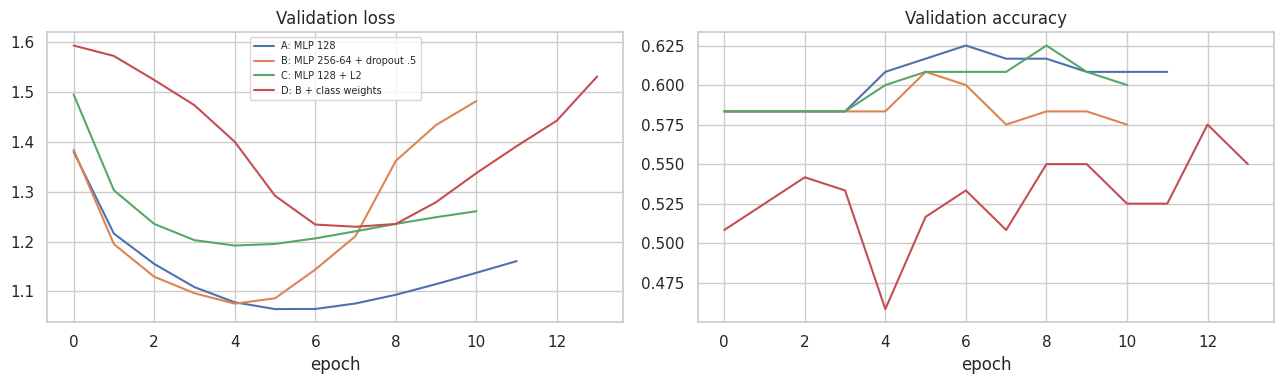

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13,4))
for e in experiments[:4]:
    axes[0].plot(e['history'].history['val_loss'], label=e['name'])
    axes[1].plot(e['history'].history['val_accuracy'], label=e['name'])
axes[0].set(title='Validation loss', xlabel='epoch'); axes[1].set(title='Validation accuracy', xlabel='epoch'); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

Selected by validation macro-F1: F: D with RMSprop

=== Classification report: F: D with RMSprop ===
              precision    recall  f1-score   support

          1★       0.32      0.35      0.33        17
          2★       0.00      0.00      0.00        10
          3★       0.29      0.21      0.24        19
          4★       0.34      0.34      0.34        38
          5★       0.66      0.71      0.68       116

    accuracy                           0.53       200
   macro avg       0.32      0.32      0.32       200
weighted avg       0.50      0.53      0.51       200



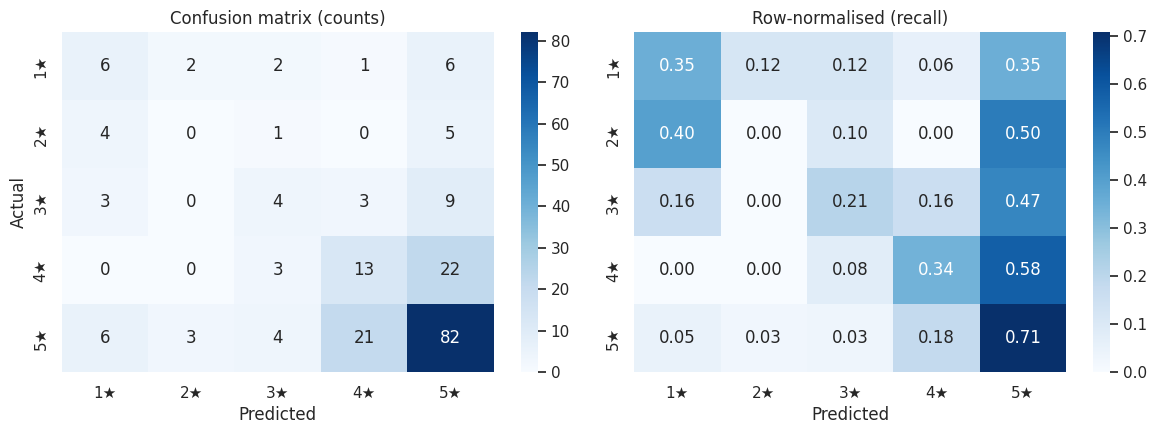

Exact: 52.5% | within 1 star: 80.5%
3-class sentiment accuracy (neg/neu/pos): 77.0%


In [27]:
# Pick the final model by validation macro-F1 (not test!) and evaluate it on the test set
best = max(experiments, key=lambda e: e['val_f1'])   # select on VALIDATION macro-F1: plain accuracy would reward predicting 5-star for everything
print('Selected by validation macro-F1:', best['name'])
final = best
labels = ['1★','2★','3★','4★','5★']
print('\n=== Classification report:', final['name'], '===')
print(classification_report(yte, final['pred'], target_names=labels, zero_division=0))

cm = confusion_matrix(yte, final['pred']); cmn = cm / cm.sum(1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[0]); axes[0].set(title='Confusion matrix (counts)', xlabel='Predicted', ylabel='Actual')
sns.heatmap(cmn, annot=True, fmt='.2f', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[1]); axes[1].set(title='Row-normalised (recall)', xlabel='Predicted')
plt.tight_layout(); plt.show()

# How far off are the misses? ("within one star" is often the practical metric)
err = np.abs(final['pred'] - yte.values)
print('Exact: %.1f%% | within 1 star: %.1f%%' % ((err==0).mean()*100, (err<=1).mean()*100))
# Collapse to the 3 sentiment buckets
to3 = lambda a: np.where(a<=1,0,np.where(a==2,1,2))
print('3-class sentiment accuracy (neg/neu/pos): %.1f%%' % (accuracy_score(to3(yte.values), to3(final['pred']))*100))

### Reflection – Part 3
**What the numbers show.** The best-performing test numbers need context: the *majority-class baseline* (always predict 5★) already scores **58.2%** accuracy, so accuracy alone is misleading here. This is why I select models on **validation macro-F1**.
- The plain MLPs (A–C) reached 58–60% test accuracy, but only by predicting almost everything as 5★ (macro-F1 0.15–0.22).
- **Class weighting** (D–F) trades accuracy for balance: accuracy drops to 50–54% but macro-F1 rises to 0.30–0.34. The selected model **F (RMSprop + dropout + class weights)** reaches 54% accuracy, macro-F1 0.34.
- Predictions are rarely far off: **81% are within one star** and **79% are correct when collapsed to negative/neutral/positive**.

**Per-class behaviour.** 5★ is easiest (F1 0.69), because it is the dominant class. 1★ is decent (F1 0.41), which fits Part 1: angry reviews use distinctive vocabulary (*return, customer service, useless*). **2★ is never predicted correctly** (F1 0.00, n = 10 in the test set), and 3★/4★ get confused with their neighbours: these middle ratings mix praise and complaints in the same text, so a bag-of-words model has little to separate them.

**Overfitting.** Training accuracy reaches 96–99% within about 11–16 epochs while validation accuracy stays near 60%; with 3,000 features and only 677 training reviews the network memorises quickly. Dropout, L2 and early stopping reduced but did not remove this gap. SGD (E) overfit least (83% train) but also learned slowly.

**Two frameworks.** The same architecture built in PyTorch gives test accuracy 0.585 and macro-F1 0.337, against 0.540 and 0.339 for Keras. Macro-F1 is essentially identical, and the accuracy gap (about 9 reviews out of 200) is the kind of difference that random initialisation and mini-batch order produce; neither framework is better. Both fail on the same classes: neither predicts 2★ reliably (F1 0.00 Keras, 0.14 PyTorch on only 10 test reviews) and both separate 5★ from the rest best.

**Benchmark.** A class-weighted logistic regression reaches macro-F1 **0.38**, slightly better than the best MLP (0.34): with this little data, a simpler model is at least as good. The small test set (200 reviews, only 10 two-star) means differences of a few points are within noise.

**Ways to improve.** More data (especially 1–3★), pre-trained embeddings or a fine-tuned transformer to capture negation and mixed sentiment, merging into 3 sentiment classes (79% accuracy already), treating rating as ordinal (regression or ordinal loss, since 1★ vs 5★ errors should cost more than 4★ vs 5★), cross-validation for more reliable comparisons, and separating topic from sentiment by including `product_id`/category features.

## Summary of findings
1. **NLP:** The reviews are mostly about e-readers/tablets and TV mounts. Negative reviews focus on returns, billing/customer service and delivery, plus battery life and a limited app store. Positive reviews focus on features that work (HDMI, mounting, reading). Word frequency reflects *topic* as much as *sentiment*.
2. **Time series:** Volume grew from 2010 to a 2013 peak and ratings improved from ~3.9 to ~4.3. Counts need first differencing (d = 1) and show a moderate December/January seasonal peak; ARIMA(1,1,1)/(0,1,1) fit well but only marginally beat a naive forecast, so forecasts should be used as ranges.
3. **Neural networks:** A TF-IDF MLP beats the majority baseline only on macro-F1 once class weights are used, and is matched by logistic regression. It gets the broad sentiment right (79%, within one star 81%) but cannot separate neighbouring middle ratings. The same network built in PyTorch and Keras gives matching macro-F1 (0.34), so the limits come from the data, not the framework. More data or pre-trained language models are the clearest next steps.